# VERIONCO — Notebook 06: Hypothesis & Planners (Guideline-Aware, API-Backed)

**Purpose:** Generate competing hypotheses and four treatment plans per patient,
using Gemini 3.5 Flash-Lite grounded strictly in NB05 retrieval evidence including
a guideline corpus (ESMO 2025, ASCO 2026, NICE NG122).

**Design principles:**
- Two API calls per patient: (A) hypotheses, (B) plan synthesis.
- Every plan item cites a real `source_id` from NB05.
- Guideline citations use `source="guideline"` and populate `guideline_plan.items`.
- Support and counter evidence kept separate and channel-tagged.
- All LLM outputs cached by (patient, agent, model, prompt_version, evidence_hash).
- Deterministic fallback when API fails (`LLM_MODE="none"` or on error).
- Restartable: cached patients skipped instantly.
- JSON repairs via `json-repair` + custom closure for truncated responses.
- Fail-fast on unrecoverable JSON decode errors (no wasted retries).

**Leakage contract:** every artifact keyed by `patient_id`.

**Downstream handoff:** NB07 consumes `plans_per_patient/{pid}.json` for
red-teaming and blind second opinion. Guideline items are identifiable by
`citation` starting with `guideline:`.

In [1]:

# Detect environment
IS_KAGGLE = Path("/kaggle").exists()

def find_dir(candidates, fallback):
    for c in candidates:
        p = Path(c)
        if p.exists():
            return p
    return Path(fallback)

# ============================================================
# CONFIGURATION  ← edit only this cell
# ============================================================
from pathlib import Path
import os, gc, sys, json, re, time, gc, hashlib, math
from datetime import datetime, timezone
from collections import defaultdict, Counter

import numpy as np
import pandas as pd

IS_KAGGLE = Path("/kaggle").exists()
OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if IS_KAGGLE else Path("./VERIONCO_outputs")
NB_OUTPUT = OUTPUT_ROOT / "06"

PATHS = {
    "nb00":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00").exists()) else OUTPUT_ROOT / "00",
    "nb01":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-01") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-01").exists()) else OUTPUT_ROOT / "01",
    "nb02":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02").exists()) else OUTPUT_ROOT / "02",
    "nb03":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03").exists()) else OUTPUT_ROOT / "03",
    "nb04":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04").exists()) else OUTPUT_ROOT / "04",
    "nb05":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05").exists()) else OUTPUT_ROOT / "05",
    "retrieval":  Path("/kaggle/input/datasets/ayushsrivastava2000/raw-retrival") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/raw-retrival").exists()) else Path("./data/retrieval"),
    "guidelines": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus").exists()) else Path("./data/retrieval"),
}

OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if Path("/kaggle").exists() else Path("./VERIONCO_outputs")
NB_OUTPUT       = OUTPUT_ROOT / "06"
NB_OUTPUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints" / "06"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

CACHE_DIR = CHECKPOINT_ROOT / "llm_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RAW_LOG   = CHECKPOINT_ROOT / "llm_raw_calls.jsonl"

PROJECT  = "VERIONCO"
NOTEBOOK = "06_hypothesis_and_planners"

# ---- LLM settings -------------------------------------------
LLM_MODE          = "api"          # "api" | "mock" | "none"
LLM_MODEL         = "gemini-1.5-flash"  # standard fast model (or gemini-2.0-flash / gemini-1.5-pro)
TEMPERATURE       = 0.2
MAX_OUTPUT_TOKENS = 2048

# Multi-Key & Rate-Limiting Configuration (8 Keys Support)
MAX_RPM_PER_KEY   = 15             # Free tier = 15 RPM per key; Paid = 1000+
KEY_COOLDOWN_SEC  = 60.0           # Cooldown seconds when 429 quota is hit

API_KEY_NAMES = [
    "GEMINI_API_KEY",
    "GEMINI_API_KEY_2",
    "GEMINI_API_KEY_3",
    "GEMINI_API_KEY_4",
    "GEMINI_API_KEY_5",
    "GEMINI_API_KEY_6",
    "GEMINI_API_KEY_7",
    "GEMINI_API_KEY_8",
]

# You can also directly paste keys here if running locally on PC:
MANUAL_API_KEYS = [
    # "AIzaSy...",
]

# ---- Run controls -------------------------------------------
MAX_PATIENTS        = None  # Full dataset: 478 cases (None = no cap, processes all cohort patients)
TIME_BUDGET_S       = 10 * 3600
SLEEP_BETWEEN_CALLS = 4.5

# ---- Evidence compression -----------------------------------
TOP_GENES          = 20
TOP_RESISTANCE     = 5
TOP_CONFLICTS      = 10
TOP_SUPPORT_HITS   = 5
TOP_COUNTER_HITS   = 5
TOP_GUIDELINE_HITS = 5
MAX_HYPOTHESES     = 3

for k, v in PATHS.items():
    print(f"{k:10s} | {v} | exists={v.exists()}")

missing = [k for k, v in PATHS.items() if not v.exists()]
assert not missing, f"Missing input roots: {missing}"
print(f"\nOutput:      {NB_OUTPUT}")
print(f"Cache:       {CACHE_DIR}")
print(f"LLM mode:    {LLM_MODE} | model={LLM_MODEL} | prompt_version={PROMPT_VERSION}")

nb00       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00 | exists=True
nb01       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-01 | exists=True
nb02       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02 | exists=True
nb03       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03 | exists=True
nb04       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04 | exists=True
nb05       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05 | exists=True
retrieval  | /kaggle/input/datasets/ayushsrivastava2000/raw-retrival | exists=True
guidelines | /kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus | exists=True

Output:      /kaggle/working/VERIONCO_outputs/06
Cache:       /kaggle/working/VERIONCO_outputs/checkpoints/06/llm_cache
LLM mode:    api | model=gemini-3.5-flash-lite | prompt_version=06_v4


In [2]:
import os, sys, json
import pandas as pd
from datetime import datetime, timezone

def load_available_keys(names, manual_keys=None):
    found = []
    
    # 0. Try central gemini_api_keys.json file (Single common file for all notebooks)
    key_file_candidates = [
        Path("gemini_api_keys.json"),
        Path("../gemini_api_keys.json"),
        Path("./data/gemini_api_keys.json"),
        Path("/kaggle/working/gemini_api_keys.json"),
        Path("/kaggle/input/gemini_api_keys.json"),
    ]
    for kfc in key_file_candidates:
        if kfc.exists():
            try:
                with open(kfc, "r", encoding="utf-8") as f:
                    content = json.load(f)
                    if isinstance(content, list):
                        for idx, k in enumerate(content, 1):
                            k_str = str(k).strip()
                            if len(k_str) > 10 and not k_str.startswith("YOUR_") and not any(key == k_str for _, key in found):
                                found.append((f"COMMON_FILE_KEY_{idx}", k_str))
                                print(f"✓ Key #{idx} loaded from common file {kfc.name} (length={len(k_str)})")
                        if found:
                            break
            except Exception as e:
                print(f"Warning: could not read {kfc}: {e}")

    # 1. Try Kaggle UserSecretsClient
    try:
        from kaggle_secrets import UserSecretsClient
        secrets = UserSecretsClient()
        for name in names:
            try:
                k = secrets.get_secret(name)
                if k and len(k) > 10 and not any(key == k.strip() for _, key in found):
                    found.append((name, k.strip()))
                    print(f"✓ {name} loaded from Kaggle Secrets (length={len(k)})")
            except Exception:
                pass
    except Exception:
        pass

    # 2. Try OS Environment variables
    for name in names:
        if name in os.environ and not any(n == name for n, _ in found):
            k = os.environ[name].strip()
            if len(k) > 10 and not any(key == k for _, key in found):
                found.append((name, k))
                print(f"✓ {name} loaded from environment (length={len(k)})")

    # 3. Add manual keys if provided
    if manual_keys:
        for idx, k in enumerate(manual_keys, 1):
            k_str = str(k).strip()
            if len(k_str) > 10 and not k_str.startswith("YOUR_") and not any(key == k_str for _, key in found):
                name = f"MANUAL_KEY_{idx}"
                found.append((name, k_str))
                print(f"✓ {name} loaded manually (length={len(k_str)})")

    return found

AVAILABLE_KEYS = load_available_keys(API_KEY_NAMES, MANUAL_API_KEYS) if LLM_MODE == "api" else []

if not AVAILABLE_KEYS:
    print("\n⚠️  No API keys available. Falling back to LLM_MODE='none'.")
    LLM_MODE = "none"
else:
    print(f"\n>>> Loaded {len(AVAILABLE_KEYS)} active API keys!")
    print(f">>> Aggregate throughput capacity: {len(AVAILABLE_KEYS) * MAX_RPM_PER_KEY} RPM ({len(AVAILABLE_KEYS) * MAX_RPM_PER_KEY / 60.0:.2f} calls/sec)")

print(json.dumps({
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "llm_mode": LLM_MODE,
    "n_keys_loaded": len(AVAILABLE_KEYS),
}, indent=2))


,package,available
0,pandas,True
1,numpy,True
2,google.generativeai,True


✓ GEMINI_API_KEY loaded (length=53)
{
  "timestamp_utc": "2026-09-26T00:26:59.270930+00:00",
  "python": "3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]",
  "llm_mode": "api"
}


In [3]:
!pip install -q --upgrade google-generativeai
!pip install -q json-repair

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.3/51.3 kB 2.2 MB/s eta 0:00:00


In [4]:
# ============================================================
# LOAD — all upstream artifacts (00-05)
# ============================================================
t0 = time.time()

def _read_csv(p, **kw):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return pd.DataFrame()
    return pd.read_csv(p, **kw)

def _read_json(p):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return {}
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)

# --- NB00 ---
cohort = _read_csv(PATHS["nb00"] / "cohort_joined_wsi.csv")
if "filename" in cohort.columns and "file_name" not in cohort.columns:
    cohort = cohort.rename(columns={"filename": "file_name"})
patient_set = set(cohort["patient_id"].astype(str).unique())
N_CASES, N_PATIENTS = len(cohort), len(patient_set)
print(f"[00] cohort: {N_CASES} cases | {N_PATIENTS} patients")

# --- NB02 ---
mutations    = _read_csv(PATHS["nb02"] / "patient_mutations.csv", low_memory=False)
gene_summary = _read_csv(PATHS["nb02"] / "gene_level_summary.csv")
civic_var    = _read_csv(PATHS["nb02"] / "civic_matches_VARIANT_LEVEL.csv")
civic_gene   = _read_csv(PATHS["nb02"] / "civic_matches_GENE_LEVEL_WARNING_NOT_CLINICAL.csv")
resistance   = _read_csv(PATHS["nb02"] / "resistance_evidence.csv", low_memory=False)
civic_lim    = _read_json(PATHS["nb02"] / "civic_data_limitation.json")
print(f"[02] mutations={mutations.shape} genes={gene_summary.shape} "
      f"civic_var={civic_var.shape} civic_gene={civic_gene.shape} "
      f"resistance={resistance.shape}")

# --- NB03 ---
clinical_features = _read_csv(PATHS["nb03"] / "clinical_features.csv")
clin_lim          = _read_json(PATHS["nb03"] / "clinical_data_limitation.json")
print(f"[03] clinical_features={clinical_features.shape}")

# --- NB04 ---
conflicts  = _read_csv(PATHS["nb04"] / "conflicts.csv")
ev_nodes   = _read_csv(PATHS["nb04"] / "evidence_nodes.csv", low_memory=False)
nb04_qc    = _read_json(PATHS["nb04"] / "evidence_graph_qc_report.json")
print(f"[04] conflicts={conflicts.shape} nodes={ev_nodes.shape}")

# --- NB05 ---
retrieval_hits = _read_csv(PATHS["nb05"] / "retrieval_hits.csv", low_memory=False)
queries        = _read_csv(PATHS["nb05"] / "queries.csv")
balance        = _read_csv(PATHS["nb05"] / "support_counter_balance.csv")
nb05_qc        = _read_json(PATHS["nb05"] / "retrieval_qc_report.json")
print(f"[05] retrieval_hits={retrieval_hits.shape} queries={queries.shape} "
      f"balance={balance.shape}")

# --- Sanity: guideline coverage ---
if len(retrieval_hits):
    src_counts = retrieval_hits["source"].value_counts().to_dict()
    print(f"[05] source distribution: {src_counts}")
    n_guide = src_counts.get("guideline", 0)
    if n_guide == 0:
        print("  WARNING: no guideline hits in retrieval_hits.csv — "
              "did you re-run NB05 with the guideline PDFs attached?")
    else:
        guide_hits = retrieval_hits[retrieval_hits["source"] == "guideline"]
        n_pat_with_guide = guide_hits["patient_id"].nunique()
        print(f"[05] guideline hits: {n_guide:,} rows across "
              f"{n_pat_with_guide} / {N_PATIENTS} patients")

print(f"\n[✓] all artifacts loaded in {time.time()-t0:.1f}s")

[00] cohort: 98 cases | 98 patients
[02] mutations=(32040, 119) genes=(29676, 5) civic_var=(80, 14) civic_gene=(18776, 14) resistance=(6073, 5)
[03] clinical_features=(98, 33)
[04] conflicts=(214, 16) nodes=(71806, 32)
[05] retrieval_hits=(47158, 13) queries=(1814, 5) balance=(1814, 6)
[05] source distribution: {'pubmed': 29449, 'guideline': 10884, 'clinicaltrials': 4999, 'civic': 1826}
[05] guideline hits: 10,884 rows across 98 / 98 patients

[✓] all artifacts loaded in 2.3s


In [5]:
# ============================================================
# DETERMINISTIC LAYER — baseline plans from evidence only
# ============================================================
import ast

SEVERITY_RANK = {"high": 3, "medium": 2, "low": 1}
MIN_RES_GENE_OVERLAP = 2

def _filter_by_patient(df, pid):
    """Safe filter: only filter if df non-empty AND has patient_id column."""
    if not isinstance(df, pd.DataFrame) or len(df) == 0:
        return pd.DataFrame()
    if "patient_id" not in df.columns:
        return pd.DataFrame()
    return df[df["patient_id"].astype(str) == str(pid)]

def _parse_genes_mentioned(raw):
    """Resistance genes_mentioned may be a JSON list string or a plain list."""
    if isinstance(raw, list):
        return [str(g).upper() for g in raw if g]
    if not isinstance(raw, str) or not raw.strip():
        return []
    s = raw.strip()
    try:
        if s.startswith("["):
            return [str(g).upper() for g in ast.literal_eval(s) if g]
        return [g.strip().upper() for g in s.split(",") if g.strip()]
    except Exception:
        return [s.upper()]

def resistance_for_patient(pid, patient_genes_upper):
    """Associate resistance records to a patient via gene overlap."""
    if not len(resistance) or "genes_mentioned" not in resistance.columns:
        return pd.DataFrame()
    if not patient_genes_upper:
        return pd.DataFrame()
    hits = []
    for _, r in resistance.iterrows():
        rec_genes = set(_parse_genes_mentioned(r.get("genes_mentioned", "")))
        if len(rec_genes & patient_genes_upper) >= MIN_RES_GENE_OVERLAP:
            hits.append(r)
        if len(hits) >= TOP_RESISTANCE:
            break
    return pd.DataFrame(hits) if hits else pd.DataFrame()

def get_patient_evidence(pid):
    """Assemble a compact evidence pack for one patient."""
    p_muts       = _filter_by_patient(mutations, pid)
    p_civic_var  = _filter_by_patient(civic_var, pid)
    p_civic_gene = _filter_by_patient(civic_gene, pid)
    p_clin       = _filter_by_patient(clinical_features, pid)
    p_conf       = _filter_by_patient(conflicts, pid)
    p_hits       = _filter_by_patient(retrieval_hits, pid)

    if len(p_muts) and "tumor_vaf" in p_muts.columns:
        p_muts_sorted = p_muts.sort_values("tumor_vaf", ascending=False, na_position="last")
    else:
        p_muts_sorted = p_muts

    top_genes = []
    seen = set()
    for _, r in p_muts_sorted.iterrows():
        g = str(r.get("Hugo_Symbol", "")).strip()
        if g and g.upper() not in seen:
            seen.add(g.upper())
            top_genes.append({
                "gene": g,
                "variant": str(r.get("variant_canonical", ""))[:80],
                "vaf": float(r["tumor_vaf"]) if pd.notna(r.get("tumor_vaf")) else None,
                "classification": r.get("Variant_Classification"),
            })
        if len(top_genes) >= TOP_GENES:
            break

    patient_genes_upper = {g["gene"].upper() for g in top_genes}
    p_res = resistance_for_patient(pid, patient_genes_upper)

    clin = p_clin.iloc[0].to_dict() if len(p_clin) else {}

    conf_list = []
    if len(p_conf):
        p_conf = p_conf[p_conf["severity"].isin(["high", "medium"])]
        p_conf = p_conf.head(TOP_CONFLICTS)
        conf_list = p_conf[["conflict_type", "severity", "description"]].to_dict("records")

    # Split hits by channel AND by source
    support_hits_all = p_hits[p_hits["retrieval_channel"] == "support"] if len(p_hits) else pd.DataFrame()
    counter_hits_all = p_hits[p_hits["retrieval_channel"] == "counter"] if len(p_hits) else pd.DataFrame()

    guideline_hits = pd.DataFrame()
    if len(p_hits) and "source" in p_hits.columns:
        guideline_hits = p_hits[p_hits["source"] == "guideline"]

    return {
        "patient_id": pid,
        "clinical": clin,
        "top_genes": top_genes,
        "civic_variant_matches": p_civic_var.head(10).to_dict("records") if len(p_civic_var) else [],
        "civic_gene_level_count": len(p_civic_gene),
        "resistance": p_res.to_dict("records") if len(p_res) else [],
        "conflicts": conf_list,
        "support_hits": support_hits_all.head(TOP_SUPPORT_HITS).to_dict("records") if len(support_hits_all) else [],
        "counter_hits": counter_hits_all.head(TOP_COUNTER_HITS).to_dict("records") if len(counter_hits_all) else [],
        "guideline_hits": guideline_hits.head(TOP_GUIDELINE_HITS).to_dict("records") if len(guideline_hits) else [],
    }

def baseline_evidence_plan(pack):
    items = []
    for h in pack["support_hits"]:
        items.append({
            "action": f"Consider evidence from {h['source']}:{h['source_id']}",
            "citation": f"{h['source']}:{h['source_id']}",
            "channel": "support",
            "source_url": h.get("source_url", ""),
            "rank": h.get("rank"),
            "score": round(float(h.get("score", 0)), 4),
            "title": str(h.get("title", ""))[:200],
        })
    for h in pack["counter_hits"]:
        items.append({
            "action": f"Consider counter-evidence from {h['source']}:{h['source_id']}",
            "citation": f"{h['source']}:{h['source_id']}",
            "channel": "counter",
            "source_url": h.get("source_url", ""),
            "rank": h.get("rank"),
            "score": round(float(h.get("score", 0)), 4),
            "title": str(h.get("title", ""))[:200],
        })
    return {"items": items, "caveats": []}

def baseline_guideline_plan(pack):
    items = []
    for h in pack["guideline_hits"]:
        items.append({
            "recommendation": str(h.get("title", ""))[:200],
            "citation": f"guideline:{h['source_id']}",
            "strength": "unspecified",
        })
    caveats = [] if items else ["guideline_evidence_unavailable"]
    return {"items": items, "caveats": caveats}

def baseline_patient_plan(pack):
    clin = pack["clinical"]
    items, contras = [], []
    stage = clin.get("stage_str")
    age   = clin.get("age")
    tmb   = clin.get("tmb")
    msi   = clin.get("msi_score")

    if stage:
        items.append({"action": f"Consider stage-appropriate therapy for {stage}",
                       "rationale": f"Stage recorded as {stage}"})
    else:
        items.append({"action": "Stage unknown — MDT review required",
                       "rationale": "missing_clinical_stage conflict present"})

    if pd.notna(age) and float(age) > 75:
        contras.append("Consider age-related toxicity risk (>75)")

    if pd.notna(tmb) and float(tmb) > 10:
        items.append({"action": "Consider immunotherapy given elevated TMB",
                       "rationale": f"TMB={tmb}"})

    if pd.notna(msi) and float(msi) > 0.5:
        items.append({"action": "Consider MSI-high pathway", "rationale": f"MSI={msi}"})

    return {"items": items, "contraindications": contras}

def baseline_trial_plan(pack):
    ncts = []
    for h in pack["support_hits"] + pack["counter_hits"]:
        if h.get("source") == "clinicaltrials":
            ncts.append({
                "nct_id": h["source_id"],
                "title": str(h.get("title", ""))[:200],
                "channel": h["retrieval_channel"],
                "citation": f"clinicaltrials:{h['source_id']}",
            })
    return {"items": ncts, "nct_ids": [n["nct_id"] for n in ncts],
            "rationale": [], "candidates": ncts}

def baseline_hypotheses(pack):
    hyps = []
    for g in pack["top_genes"][:MAX_HYPOTHESES]:
        hyps.append({
            "hypothesis": f"Functional relevance of {g['gene']} mutation in LUAD",
            "supporting_evidence": [f"mutation:{g['gene']}"],
            "contradicting_evidence": [],
            "confidence": None,
            "provenance": "deterministic_baseline",
        })
    for r in pack["resistance"][:2]:
        hyps.append({
            "hypothesis": f"Possible resistance mechanism linked to {str(r.get('genes_mentioned',''))[:80]}",
            "supporting_evidence": [],
            "contradicting_evidence": [],
            "confidence": None,
            "provenance": "deterministic_baseline",
        })
    return {"hypotheses": hyps[:MAX_HYPOTHESES]}

def build_baseline(pid):
    pack = get_patient_evidence(pid)
    return {
        "patient_id": pid,
        "hypotheses": baseline_hypotheses(pack),
        "guideline_plan": baseline_guideline_plan(pack),
        "evidence_plan": baseline_evidence_plan(pack),
        "patient_specific_plan": baseline_patient_plan(pack),
        "trial_plan": baseline_trial_plan(pack),
        "llm_status": "deterministic_only",
        "provenance": {"notebook": NOTEBOOK, "layer": "deterministic"},
    }

print("✓ deterministic layer defined")

✓ deterministic layer defined


In [7]:
# ============================================================
# LLM CLIENT — 8-Key Load-Balanced & Per-Minute Rate-Limited
# ============================================================
import subprocess, time, hashlib, json, re
from collections import deque
subprocess.run(["pip", "install", "-q", "json-repair"], check=True)
from json_repair import repair_json

def _hash(*parts):
    h = hashlib.sha256()
    for p in parts:
        h.update(str(p).encode("utf-8"))
    return h.hexdigest()[:16]

def hash_evidence(pack):
    canonical = json.dumps(pack, sort_keys=True, default=str)
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()[:16]

class LLMError(Exception):
    pass

class RateLimitedMultiKeyGeminiClient:
    def __init__(self, keys, model=LLM_MODEL, max_rpm_per_key=MAX_RPM_PER_KEY, max_retries=12):
        import google.generativeai as genai
        self._genai = genai
        self.model_name = model
        self.max_retries = max_retries
        self.max_rpm = max_rpm_per_key

        if not keys:
            raise LLMError("No API keys provided")

        self.keys = list(keys)
        self.n_keys = len(self.keys)

        # Sliding window timestamp queues for each key (last 60s)
        self.key_history = {name: deque() for name, _ in self.keys}
        self.key_cooldown_until = {name: 0.0 for name, _ in self.keys}
        self.key_calls = {name: 0 for name, _ in self.keys}
        self.key_errors = {name: 0 for name, _ in self.keys}
        self.key_429s = {name: 0 for name, _ in self.keys}

        self.calls_this_run = 0
        self.cache_hits = 0
        self.json_repairs = 0
        self.rotations = 0
        self.exhaustion_events = 0
        self.exhausted = {name: False for name, _ in self.keys}

        self.tokens_in = 0
        self.tokens_out = 0

        self.current_idx = 0
        self._configure_key(0)

    def _configure_key(self, idx):
        name, key = self.keys[idx]
        self._genai.configure(api_key=key)
        self._current_key_name = name

    def _clean_history(self, name, now):
        q = self.key_history[name]
        cutoff = now - 60.0
        while q and q[0] < cutoff:
            q.popleft()

    def _find_available_key(self):
        """Find a key that is not in cooldown and has < max_rpm in the last 60s."""
        while True:
            now = time.time()
            best_key_idx = None
            min_calls = 999999

            for offset in range(self.n_keys):
                idx = (self.current_idx + offset) % self.n_keys
                name, _ = self.keys[idx]

                if now < self.key_cooldown_until[name]:
                    continue

                self._clean_history(name, now)
                current_rpm = len(self.key_history[name])

                if current_rpm < self.max_rpm:
                    if current_rpm < min_calls:
                        min_calls = current_rpm
                        best_key_idx = idx
                        if current_rpm == 0:
                            break

            if best_key_idx is not None:
                if best_key_idx != self.current_idx:
                    self.current_idx = best_key_idx
                    self.rotations += 1
                    self._configure_key(self.current_idx)
                return self.keys[self.current_idx][0]

            # All keys full or on cooldown -> compute wait time
            earliest_free = 999999.0
            for name, _ in self.keys:
                if now < self.key_cooldown_until[name]:
                    wait_cd = self.key_cooldown_until[name] - now
                    if wait_cd < earliest_free:
                        earliest_free = wait_cd
                else:
                    self._clean_history(name, now)
                    q = self.key_history[name]
                    if q:
                        wait_rpm = 60.0 - (now - q[0]) + 0.1
                        if wait_rpm < earliest_free:
                            earliest_free = wait_rpm

            wait_time = max(0.5, min(earliest_free, 10.0))
            time.sleep(wait_time)

    def _record_429(self, key_name):
        now = time.time()
        self.key_429s[key_name] += 1
        self.exhaustion_events += 1
        self.exhausted[key_name] = True
        self.key_cooldown_until[key_name] = now + KEY_COOLDOWN_SEC
        print(f"    ⛔ Key '{key_name}' hit rate limit (429). Cooldown for {KEY_COOLDOWN_SEC:.0f}s. Rotating...")

    def _record_success(self, key_name):
        now = time.time()
        self.key_history[key_name].append(now)
        self.key_calls[key_name] += 1
        self.calls_this_run += 1

    def _cache_path(self, key):
        return CACHE_DIR / f"{key}.json"

    @staticmethod
    def _repair_with_fallback(raw):
        try:
            fixed = repair_json(raw, return_objects=False)
            json.loads(fixed)
            return fixed
        except Exception:
            pass
        s = raw.rstrip()
        try:
            json.loads(s)
            return s
        except json.JSONDecodeError:
            pass
        if s.count('"') % 2 == 1:
            s += '"'
        for opener, closer in [("{", "}"), ("[", "]")]:
            opens = s.count(opener) - s.count(closer)
            s += closer * max(0, opens)
        return s

    def generate_json(self, prompt, system_prompt, cache_key_parts):
        cache_key = _hash(*cache_key_parts)
        cp = self._cache_path(cache_key)
        if cp.exists():
            with open(cp, "r", encoding="utf-8") as f:
                self.cache_hits += 1
                return json.load(f)

        last_err = None
        attempt = 0
        while attempt < self.max_retries:
            key_name = self._find_available_key()
            try:
                model = self._genai.GenerativeModel(
                    self.model_name,
                    system_instruction=system_prompt,
                    generation_config={
                        "temperature": TEMPERATURE,
                        "max_output_tokens": MAX_OUTPUT_TOKENS,
                        "response_mime_type": "application/json",
                    },
                )
                resp = model.generate_content(prompt)
                raw = resp.text
                self._record_success(key_name)

                # token accounting
                usage = getattr(resp, "usage_metadata", None)
                if usage is not None:
                    self.tokens_in  += int(getattr(usage, "prompt_token_count", 0) or 0)
                    self.tokens_out += int(getattr(usage, "candidates_token_count", 0) or 0)

                raw_clean = re.sub(r"^```json\s*", "", raw.strip())
                raw_clean = re.sub(r"\s*```$", "", raw_clean)

                try:
                    data = json.loads(raw_clean)
                except json.JSONDecodeError:
                    repaired = self._repair_with_fallback(raw_clean)
                    data = json.loads(repaired)
                    self.json_repairs += 1

                # Save cache
                with open(cp, "w", encoding="utf-8") as f:
                    json.dump(data, f, indent=2)

                # Log call
                with open(RAW_LOG, "a", encoding="utf-8") as f:
                    f.write(json.dumps({
                        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                        "cache_key": cache_key,
                        "key_used": key_name,
                        "raw_response": raw,
                    }) + "\n")

                return data

            except Exception as e:
                err_str = str(e).lower()
                if "429" in err_str or "quota" in err_str or "resource_exhausted" in err_str:
                    self._record_429(key_name)
                else:
                    self.key_errors[key_name] += 1
                    print(f"    ⚠️ Warning on {key_name}: {e}. Retrying with next key...")
                last_err = e
                attempt += 1
                time.sleep(1.0)

        raise LLMError(f"Failed after {self.max_retries} attempts across keys. Last error: {last_err}")


llm = RateLimitedMultiKeyGeminiClient(AVAILABLE_KEYS) if LLM_MODE == "api" and AVAILABLE_KEYS else None


✓ LLM client ready: True


In [8]:
# ============================================================
# PROMPTS v4 — guideline-forcing, explicit enumeration
# ============================================================

HYPOTHESIS_SYSTEM_PROMPT = """You are a research assistant for a decision-support system.
Output ONLY valid JSON. Do not invent papers, trials, guidelines, or clinical facts.
Cite only source_ids explicitly provided in the input.
If evidence is missing, write "no_supporting_retrieval_hit_found".
Each hypothesis must cite at least one source_id from the input, or explicitly state
"no_supporting_retrieval_hit_found".
Keep output concise but complete. Do not truncate reasoning to save tokens."""

PLAN_SYSTEM_PROMPT = """You are a research assistant for a decision-support system.
Output ONLY valid JSON. Do not invent papers, trials, guidelines, or clinical facts.
Cite only source_ids explicitly provided in the input.
Never claim trial eligibility when required information is missing.
Keep output concise but complete. Do not truncate reasoning to save tokens.

CRITICAL ENUMERATION RULES:
- Produce exactly one evidence_plan item for EACH support citation listed in the input.
- Produce exactly one evidence_plan item for EACH counter citation listed in the input.
- Tag each item with "channel": "support" or "channel": "counter".
- Do NOT skip citations. If a citation does not apply, include it with rationale="not_applicable".
- patient_specific_plan MUST contain at least 2 items unless the patient has no clinical data.
- trial_plan.nct_ids MUST include every NCT id that appears in the support or counter citations.

GUIDELINE-SPECIFIC RULES (STRICT):
- Guideline citations have source="guideline" and source_id like "esmo_mnsclc_2025:0042".
- If one or more GUIDELINE_CITATIONS are listed in the input, you MUST populate
  guideline_plan.items with at least one entry. Do NOT set the caveat when citations exist.
- Populate guideline_plan.items with one entry per guideline citation.
- If a guideline passage seems only partially applicable, include it with strength="partial_match"
  rather than dropping it.
- The ONLY permitted reason to set guideline_plan.caveats=["guideline_evidence_unavailable"]
  is when the GUIDELINE_CITATIONS block contains exactly zero items.
- Do NOT paraphrase beyond what is in the citation.
- Distinguish "strong recommendation" from "weak recommendation" when the source states this."""


def _clinical_line(clin):
    return (f"age={clin.get('age')}, sex={clin.get('sex')}, "
            f"stage={clin.get('stage_str')}, "
            f"tmb={clin.get('tmb')}, msi={clin.get('msi_score')}, "
            f"smoking={clin.get('neo_adjuvant_treatment')}")


def _format_hits(hits, label):
    if not hits:
        return f"{label}: none"
    lines = []
    for h in hits:
        src   = h.get("source", "?")
        sid   = h.get("source_id", "?")
        title = str(h.get("title", ""))[:80]
        lines.append(f"{src}:{sid} \"{title}\"")
    return f"{label}: " + "; ".join(lines)


def build_hypothesis_prompt(pack):
    genes_line = ", ".join(g["gene"] for g in pack["top_genes"])
    civic_line = "; ".join(
        f"{m.get('gene','')} {m.get('civic_therapies','')} "
        f"(evidence_count={m.get('civic_evidence_item_count')})"
        for m in pack["civic_variant_matches"][:5]
    ) or "none"
    res_line = "; ".join(
        f"{str(r.get('genes_mentioned',''))[:60]} [{r.get('source','')}]"
        for r in pack["resistance"][:TOP_RESISTANCE]
    ) or "none"
    conf_line = "; ".join(
        f"{c['conflict_type']}({c['severity']})" for c in pack["conflicts"]
    ) or "none"

    return f"""PATIENT: {pack['patient_id']}
CANCER: LUAD
CLINICAL: {_clinical_line(pack['clinical'])}
TOP_GENES: {genes_line}
CIVIC_VARIANT_MATCHES: {civic_line}
RESISTANCE_GENES: {res_line}
CONFLICTS: {conf_line}
{_format_hits(pack['support_hits'], 'SUPPORT_HITS')}
{_format_hits(pack['counter_hits'], 'COUNTER_HITS')}
{_format_hits(pack['guideline_hits'], 'GUIDELINE_HITS')}

Generate exactly {MAX_HYPOTHESES} competing hypotheses about this patient's molecular drivers.
Each hypothesis must cite at least one of the source_ids listed above, or explicitly state
"no_supporting_retrieval_hit_found".
Return JSON:
{{"hypotheses":[
  {{"hypothesis":"...",
    "supporting_evidence":["pubmed:...","guideline:..."],
    "contradicting_evidence":["pubmed:..."],
    "confidence":0.0,
    "provenance":"llm_synthesis"}}
]}}"""


def build_plan_prompt(pack, hypo_json):
    conf_line = "; ".join(
        f"{c['conflict_type']}({c['severity']})" for c in pack["conflicts"]
    ) or "none"
    missing = []
    for k in ("age", "sex", "stage_str"):
        v = pack["clinical"].get(k)
        if v is None or (isinstance(v, float) and pd.isna(v)):
            missing.append(k)
    missing_line = ", ".join(missing) or "none"
    therapy_line = "; ".join(
        f"{m.get('gene','')}: {str(m.get('civic_therapies',''))[:60]}"
        for m in pack["civic_variant_matches"][:5]
    ) or "none"

    support_cits   = [f"{h['source']}:{h['source_id']}" for h in pack["support_hits"]]
    counter_cits   = [f"{h['source']}:{h['source_id']}" for h in pack["counter_hits"]]
    guideline_cits = [f"{h['source']}:{h['source_id']}" for h in pack["guideline_hits"]]

    def block(cits):
        if not cits:
            return "  - none"
        return "\n".join(f"  - {c}" for c in cits)

    n_support   = len(support_cits)
    n_counter   = len(counter_cits)
    n_guideline = len(guideline_cits)
    n_total     = n_support + n_counter

    # Conditional instruction block
    if n_guideline > 0:
        guide_instruction = (
            f"- guideline_plan.items MUST contain at least one entry. "
            f"You MUST NOT set the caveat because {n_guideline} guideline citations were provided.\n"
            f"- Populate guideline_plan.items with one entry per guideline citation above.\n"
            f"- If a passage seems partial, include it with strength=\"partial_match\"."
        )
    else:
        guide_instruction = (
            "- No guideline citations were provided. Set "
            "guideline_plan.caveats=[\"guideline_evidence_unavailable\"]."
        )

    return f"""PATIENT: {pack['patient_id']}
HYPOTHESES: {json.dumps(hypo_json, default=str)[:1200]}
CIVIC_THERAPIES: {therapy_line}
CONFLICTS: {conf_line}
MISSING_FIELDS: {missing_line}

GUIDELINE_CITATIONS ({n_guideline} items):
{block(guideline_cits)}

SUPPORT_CITATIONS ({n_support} items — produce exactly one evidence_plan item per citation):
{block(support_cits)}

COUNTER_CITATIONS ({n_counter} items — produce exactly one evidence_plan item per citation):
{block(counter_cits)}

REQUIRED OUTPUT:
- evidence_plan.items MUST contain exactly {n_total} entries
  ({n_support} tagged "channel":"support", {n_counter} tagged "channel":"counter")
{guide_instruction}
- patient_specific_plan.items MUST contain at least 2 entries (unless clinical data is entirely absent)
- trial_plan.nct_ids MUST include every NCT id appearing above

Return JSON:
{{"guideline_plan":{{"items":[{{"recommendation":"","citation":"guideline:...","strength":"strong|weak|partial_match|unspecified"}}],"caveats":[]}},
 "evidence_plan":{{"items":[{{"action":"","citation":"pubmed:...","channel":"support","rationale":""}}]}},
 "patient_specific_plan":{{"items":[{{"action":"","rationale":""}}],"contraindications":[]}},
 "trial_plan":{{"nct_ids":[],"rationale":[]}}}}"""

print("✓ prompt builders v4 defined")

✓ prompt builders v4 defined


In [9]:
# ============================================================
# PER-PATIENT PIPELINE — 2 LLM calls, deterministic fallback
# ============================================================

def _normalize_plan(plan, items_key="items", extra_keys=()):
    if plan is None:
        out = {items_key: []}
        for k in extra_keys:
            out[k] = []
        return out

    if isinstance(plan, list):
        out = {items_key: plan}
        for k in extra_keys:
            out[k] = []
        return out

    if isinstance(plan, dict):
        out = dict(plan)
        if items_key not in out or not isinstance(out[items_key], list):
            out[items_key] = []
        for k in extra_keys:
            if k not in out or not isinstance(out[k], list):
                out[k] = []
        return out

    out = {items_key: []}
    for k in extra_keys:
        out[k] = []
    return out


def normalize_patient_result(r):
    if not isinstance(r, dict):
        return r

    h = r.get("hypotheses")
    if isinstance(h, list):
        r["hypotheses"] = {"hypotheses": h}
    elif not isinstance(h, dict):
        r["hypotheses"] = {"hypotheses": []}
    else:
        if not isinstance(h.get("hypotheses"), list):
            h["hypotheses"] = []

    r["guideline_plan"]        = _normalize_plan(r.get("guideline_plan"),
                                                 items_key="items",
                                                 extra_keys=("caveats",))
    r["evidence_plan"]         = _normalize_plan(r.get("evidence_plan"),
                                                 items_key="items")
    r["patient_specific_plan"] = _normalize_plan(r.get("patient_specific_plan"),
                                                 items_key="items",
                                                 extra_keys=("contraindications",))
    r["trial_plan"]            = _normalize_plan(r.get("trial_plan"),
                                                 items_key="items",
                                                 extra_keys=("nct_ids", "rationale", "candidates"))
    return r


def process_patient_api(pid):
    pack = get_patient_evidence(pid)
    ev_hash = hash_evidence(pack)

    hypo = llm.generate_json(
        prompt=build_hypothesis_prompt(pack),
        system_prompt=HYPOTHESIS_SYSTEM_PROMPT,
        cache_key_parts=[pid, "hypo", PROMPT_VERSION, LLM_MODEL, ev_hash],
    )

    plan = llm.generate_json(
        prompt=build_plan_prompt(pack, hypo),
        system_prompt=PLAN_SYSTEM_PROMPT,
        cache_key_parts=[pid, "plan", PROMPT_VERSION, LLM_MODEL, ev_hash,
                         _hash(json.dumps(hypo, sort_keys=True))],
    )

    if isinstance(plan, dict):
        guideline_plan        = plan.get("guideline_plan", {})
        evidence_plan         = plan.get("evidence_plan", {})
        patient_specific_plan = plan.get("patient_specific_plan", {})
        trial_plan            = plan.get("trial_plan", {})
    elif isinstance(plan, list):
        guideline_plan        = {}
        evidence_plan         = plan
        patient_specific_plan = {}
        trial_plan            = {}
    else:
        guideline_plan        = {}
        evidence_plan         = {}
        patient_specific_plan = {}
        trial_plan            = {}

    result = {
        "patient_id": pid,
        "hypotheses": hypo,
        "guideline_plan":        guideline_plan,
        "evidence_plan":         evidence_plan,
        "patient_specific_plan": patient_specific_plan,
        "trial_plan":            trial_plan,
        "llm_status": "api_success",
        "provenance": {
            "notebook": NOTEBOOK,
            "llm_model": LLM_MODEL,
            "prompt_version": PROMPT_VERSION,
            "evidence_hash": ev_hash,
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        },
    }
    return normalize_patient_result(result)


def process_patient(pid):
    if LLM_MODE == "none" or llm is None:
        return normalize_patient_result(build_baseline(pid))
    try:
        return process_patient_api(pid)
    except LLMError as e:
        print(f"  LLM failed for {pid}: {e} — using deterministic fallback")
        out = normalize_patient_result(build_baseline(pid))
        out["llm_status"] = "failed_fallback"
        out["llm_error"] = str(e)
        return out


print("✓ per-patient pipeline + normalizer defined")

✓ per-patient pipeline + normalizer defined


In [10]:
# ============================================================
# MAIN LOOP — process all patients, checkpoint each result
# ============================================================
plans_dir = NB_OUTPUT / "plans_per_patient"
plans_dir.mkdir(parents=True, exist_ok=True)

run_start = time.time()
completed, skipped_cache, failed, pending = 0, 0, [], []

print(f"Running with PROMPT_VERSION={PROMPT_VERSION} | model={LLM_MODEL} | mode={LLM_MODE}")
print(f"Patient set: {len(patient_set)} | MAX_PATIENTS={MAX_PATIENTS}")
print(f"Expected new API calls: ~{2 * len(patient_set)}")
print("-" * 60)

for i, pid in enumerate(sorted(patient_set)):
    if MAX_PATIENTS and completed >= MAX_PATIENTS:
        pending.append(pid)
        continue

    out_path = plans_dir / f"{pid}.json"

    if out_path.exists():
        skipped_cache += 1
        completed += 1
        continue

    if time.time() - run_start > TIME_BUDGET_S:
        pending.append(pid)
        continue

    try:
        result = process_patient(pid)
        with open(out_path, "w", encoding="utf-8") as f:
            json.dump(result, f, indent=2, default=str)
        completed += 1
        if (i + 1) % 10 == 0 or i == 0:
            calls = llm.calls_this_run if llm else 0
            hits  = llm.cache_hits if llm else 0
            elapsed = time.time() - run_start
            print(f"[{i+1}/{len(patient_set)}] {pid} OK | "
                  f"calls={calls} cache_hits={hits} elapsed={elapsed:.0f}s")
    except Exception as e:
        failed.append({"patient_id": pid, "error": str(e)})
        print(f"[{i+1}] {pid} FAILED: {e}")

    if LLM_MODE == "api" and llm is not None:
        time.sleep(SLEEP_BETWEEN_CALLS)

summary = {
    "completed":          completed,
    "skipped_from_cache": skipped_cache,
    "failed":             failed,
    "pending":            pending,
    "llm_calls_this_run": llm.calls_this_run if llm else 0,
    "cache_hits":         llm.cache_hits if llm else 0,
    "json_repairs":       llm.json_repairs if llm else 0,
    "elapsed_s":          round(time.time() - run_start, 1),
    "llm_mode":           LLM_MODE,
    "llm_model":          LLM_MODEL,
    "prompt_version":     PROMPT_VERSION,
    "timestamp_utc":      datetime.now(timezone.utc).isoformat(),
}
with open(NB_OUTPUT / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 50)
print(json.dumps(summary, indent=2))
print("=" * 50)

Running with PROMPT_VERSION=06_v4 | model=gemini-3.5-flash-lite | mode=api
Patient set: 98 | MAX_PATIENTS=None
Expected new API calls: ~196
------------------------------------------------------------
[1/98] TCGA-05-4244 OK | calls=2 cache_hits=0 elapsed=29s
    JSON repaired (attempt 1)
    JSON repaired (attempt 1)
[10/98] TCGA-05-4397 OK | calls=20 cache_hits=0 elapsed=166s
    JSON repaired (attempt 1)
[20/98] TCGA-05-4422 OK | calls=40 cache_hits=0 elapsed=331s
    JSON repaired (attempt 1)
    JSON repaired (attempt 1)
[30/98] TCGA-05-5423 OK | calls=60 cache_hits=0 elapsed=603s
    JSON repaired (attempt 1)
    JSON repaired (attempt 1)
    JSON repaired (attempt 1)
[40/98] TCGA-38-4626 OK | calls=80 cache_hits=0 elapsed=777s
    JSON repaired (attempt 1)
[50/98] TCGA-44-2655 OK | calls=100 cache_hits=0 elapsed=893s
[60/98] TCGA-44-3396 OK | calls=120 cache_hits=0 elapsed=999s
[70/98] TCGA-44-6145 OK | calls=140 cache_hits=0 elapsed=1104s
[80/98] TCGA-44-7659 OK | calls=160 cach

In [11]:
# ============================================================
# FLATTEN + QC
# ============================================================
plans_dir = NB_OUTPUT / "plans_per_patient"

all_results = {}
rewritten = 0
for pid in sorted(patient_set):
    p = plans_dir / f"{pid}.json"
    if not p.exists():
        continue
    with open(p, "r", encoding="utf-8") as f:
        r = json.load(f)
    r = normalize_patient_result(r)
    all_results[pid] = r
    with open(p, "w", encoding="utf-8") as f:
        json.dump(r, f, indent=2, default=str)
    rewritten += 1

print(f"loaded {len(all_results)} patient plans | normalized+rewritten {rewritten}")

rows = []
for pid, r in all_results.items():
    hypotheses_list   = r.get("hypotheses", {}).get("hypotheses", [])
    guideline_items   = r.get("guideline_plan", {}).get("items", [])
    guideline_caveats = r.get("guideline_plan", {}).get("caveats", [])
    evidence_items    = r.get("evidence_plan", {}).get("items", [])
    patient_items     = r.get("patient_specific_plan", {}).get("items", [])
    patient_contras   = r.get("patient_specific_plan", {}).get("contraindications", [])
    trial_items       = r.get("trial_plan", {}).get("items", [])
    trial_ncts        = r.get("trial_plan", {}).get("nct_ids", [])
    trial_cands       = r.get("trial_plan", {}).get("candidates", [])

    n_support_items = sum(1 for it in evidence_items
                          if isinstance(it, dict) and it.get("channel") == "support")
    n_counter_items = sum(1 for it in evidence_items
                          if isinstance(it, dict) and it.get("channel") == "counter")

    rows.append({
        "patient_id":             pid,
        "llm_status":             r.get("llm_status"),
        "n_hypotheses":           len(hypotheses_list),
        "n_guideline_items":      len(guideline_items),
        "n_guideline_caveats":    len(guideline_caveats),
        "n_evidence_items":       len(evidence_items),
        "n_evidence_support":     n_support_items,
        "n_evidence_counter":     n_counter_items,
        "n_patient_items":        len(patient_items),
        "n_patient_contras":      len(patient_contras),
        "n_trial_candidates":     len(trial_items) + len(trial_ncts) + len(trial_cands),
        "guideline_caveats":      "; ".join(guideline_caveats or [])[:300],
        "llm_error":              str(r.get("llm_error", ""))[:200],
    })

flat_df = pd.DataFrame(rows)
flat_df.to_csv(NB_OUTPUT / "plans_flat.csv", index=False)
display(flat_df.head(20))

stats = {}
if len(flat_df):
    for col in ["n_hypotheses", "n_evidence_items", "n_evidence_support",
                "n_evidence_counter", "n_guideline_items", "n_patient_items",
                "n_patient_contras", "n_trial_candidates"]:
        if col in flat_df.columns:
            stats[col] = {
                "mean":   round(float(flat_df[col].mean()), 2),
                "median": float(flat_df[col].median()),
                "std":    round(float(flat_df[col].std()), 2),
                "min":    int(flat_df[col].min()),
                "max":    int(flat_df[col].max()),
            }

print("\n=== Distribution stats ===")
print(json.dumps(stats, indent=2))

with open(NB_OUTPUT / "plans_all.json", "w", encoding="utf-8") as f:
    json.dump(all_results, f, indent=2, default=str)

status_counts = flat_df["llm_status"].value_counts().to_dict() if len(flat_df) else {}

qc = {
    "notebook":           NOTEBOOK,
    "n_patients":         N_PATIENTS,
    "n_completed":        len(all_results),
    "status_counts":      status_counts,
    "llm_mode":           LLM_MODE,
    "llm_model":          LLM_MODEL,
    "prompt_version":     PROMPT_VERSION,
    "calls_this_run":     llm.calls_this_run if llm else 0,
    "cache_hits":         llm.cache_hits if llm else 0,
    "json_repairs":       llm.json_repairs if llm else 0,
    "distribution_stats": stats,
    "guideline_integration": {
        "guideline_items_avg_per_patient": round(
            float((flat_df["n_guideline_items"]).mean()), 2) if len(flat_df) else 0,
        "patients_with_guideline_items": int((flat_df["n_guideline_items"] > 0).sum()) if len(flat_df) else 0,
        "patients_with_guideline_caveat": int((flat_df["n_guideline_caveats"] > 0).sum()) if len(flat_df) else 0,
    },
    "limitations": [
        "LLM outputs are hypothesis generators, not clinical truth.",
        "Every plan item must be cross-checked against retrieval citations.",
        "Guideline corpus: ESMO 2025, ASCO 2026 Stage IV Driver Alt, NICE NG122.",
        "Trial eligibility is NOT decided by the LLM; deterministic matching is downstream.",
        "Support and counter evidence are kept separate and never merged.",
    ],
    "patient_leakage_note": "all artifacts keyed by patient_id",
    "normalizer_note": (
        "All plan fields normalized to dict shape {items:[], ...} because "
        "the LLM occasionally returns bare arrays despite schema instructions."
    ),
    "prompt_version_note": (
        "v1: schema-filling degenerate outputs. "
        "v2: explicit enumeration, resolved shallow plans. "
        "v3: guideline-aware with guideline_plan population. "
        "v4: guideline-forcing (mandatory items when citations present)."
    ),
}

with open(NB_OUTPUT / "planner_qc_report.json", "w", encoding="utf-8") as f:
    json.dump(qc, f, indent=2, default=str)

print("\n=== QC ===")
print(json.dumps({k: v for k, v in qc.items() if k != "distribution_stats"},
                 indent=2, default=str))

loaded 98 patient plans | normalized+rewritten 98


,patient_id,llm_status,n_hypotheses,n_guideline_items,n_guideline_caveats,n_evidence_items,n_evidence_support,n_evidence_counter,n_patient_items,n_patient_contras,n_trial_candidates,guideline_caveats,llm_error
0,TCGA-05-4244,api_success,3,5,0,10,5,5,2,1,1,,
1,TCGA-05-4245,api_success,3,5,0,10,5,5,2,1,6,,
2,TCGA-05-4249,api_success,3,5,0,10,5,5,0,0,0,,
3,TCGA-05-4250,api_success,3,5,0,10,5,5,2,0,0,,
4,TCGA-05-4382,api_success,3,5,0,10,5,5,2,1,1,,
5,TCGA-05-4384,api_success,3,5,0,10,5,5,2,0,1,,
6,TCGA-05-4390,api_success,3,5,0,10,5,5,2,1,1,,
7,TCGA-05-4395,api_success,3,5,0,10,5,5,2,0,1,,
8,TCGA-05-4396,api_success,3,5,0,10,5,5,2,0,1,,
9,TCGA-05-4397,api_success,3,5,0,10,5,5,2,0,1,,



=== Distribution stats ===
{
  "n_hypotheses": {
    "mean": 3.0,
    "median": 3.0,
    "std": 0.0,
    "min": 3,
    "max": 3
  },
  "n_evidence_items": {
    "mean": 10.0,
    "median": 10.0,
    "std": 0.0,
    "min": 10,
    "max": 10
  },
  "n_evidence_support": {
    "mean": 5.0,
    "median": 5.0,
    "std": 0.0,
    "min": 5,
    "max": 5
  },
  "n_evidence_counter": {
    "mean": 5.0,
    "median": 5.0,
    "std": 0.0,
    "min": 5,
    "max": 5
  },
  "n_guideline_items": {
    "mean": 4.99,
    "median": 5.0,
    "std": 0.1,
    "min": 4,
    "max": 5
  },
  "n_patient_items": {
    "mean": 1.98,
    "median": 2.0,
    "std": 0.2,
    "min": 0,
    "max": 2
  },
  "n_patient_contras": {
    "mean": 0.36,
    "median": 0.0,
    "std": 0.5,
    "min": 0,
    "max": 2
  },
  "n_trial_candidates": {
    "mean": 1.17,
    "median": 1.0,
    "std": 1.41,
    "min": 0,
    "max": 6
  }
}

=== QC ===
{
  "notebook": "06_hypothesis_and_planners",
  "n_patients": 98,
  "n_completed"

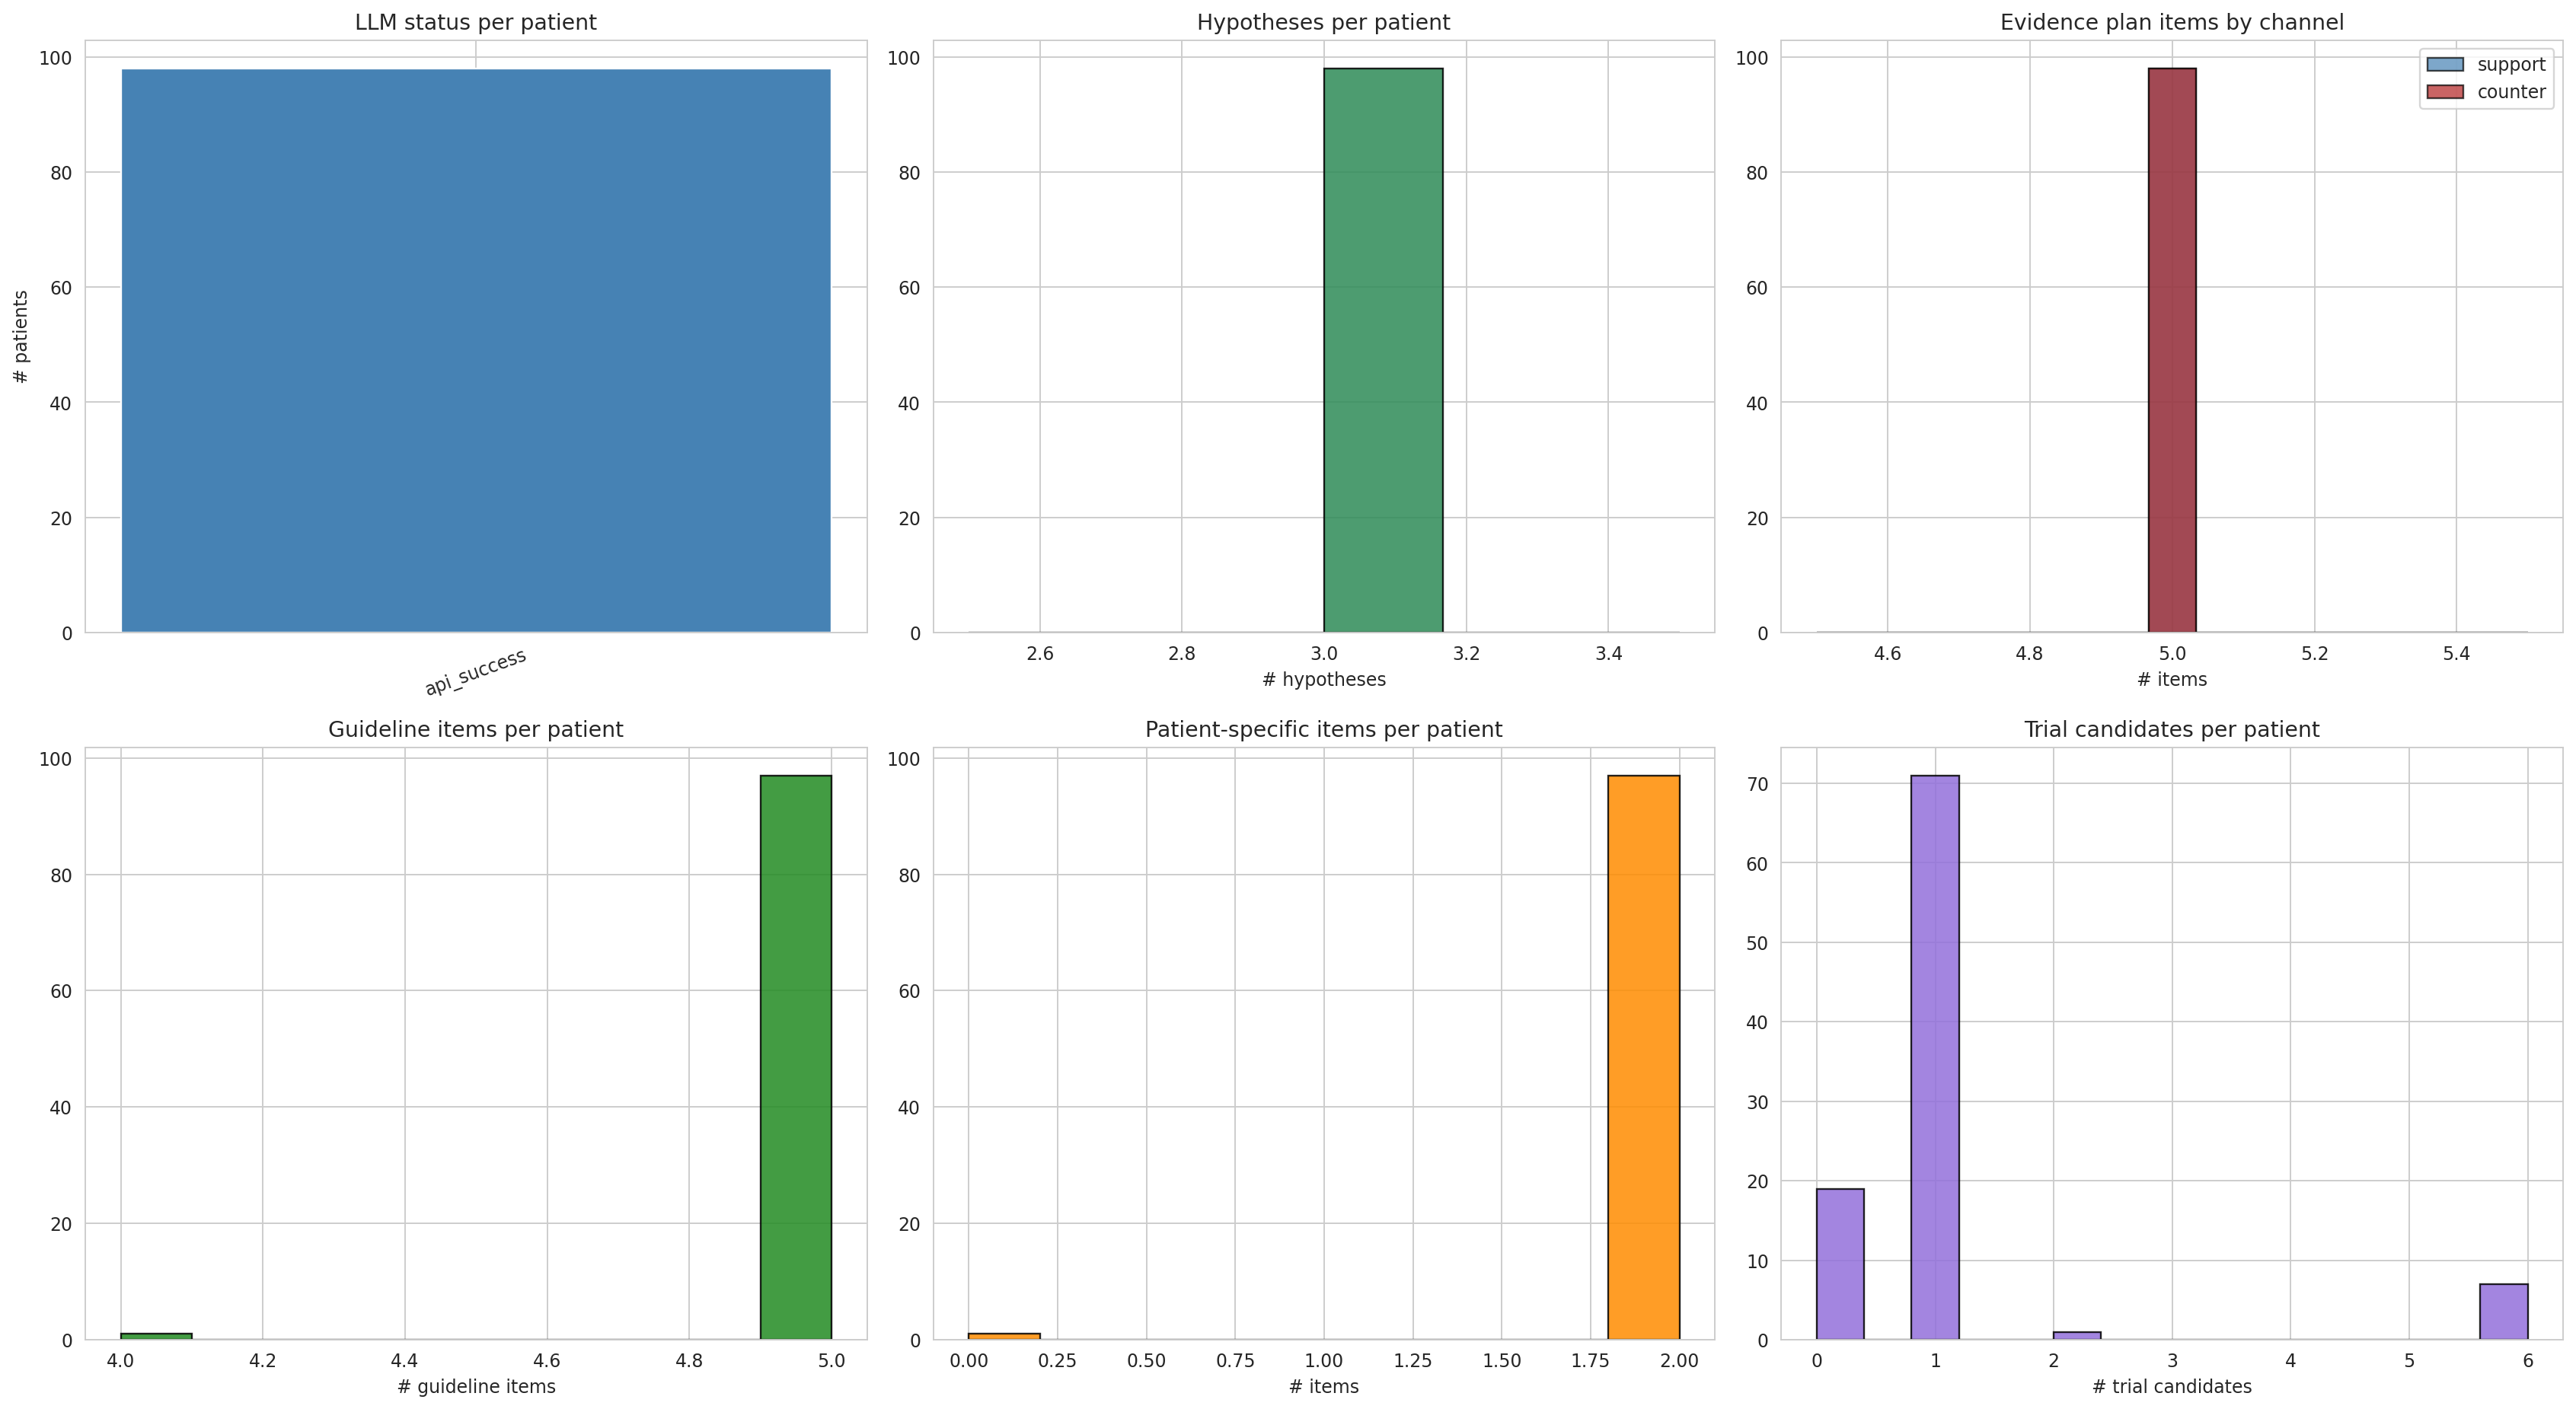

Saved: /kaggle/working/VERIONCO_outputs/06/planner_dashboard.png


,metric,mean,median,std,min,max
0,n_hypotheses,3.00,3.0,0.00,3,3
1,n_evidence_items,10.00,10.0,0.00,10,10
2,n_evidence_support,5.00,5.0,0.00,5,5
3,n_evidence_counter,5.00,5.0,0.00,5,5
4,n_guideline_items,4.99,5.0,0.10,4,5
5,n_patient_items,1.98,2.0,0.20,0,2
6,n_patient_contras,0.36,0.0,0.50,0,2
7,n_trial_candidates,1.17,1.0,1.41,0,6


In [12]:
# ============================================================
# DASHBOARD
# ============================================================
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

from IPython.display import Image, display as _display

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

sc = flat_df["llm_status"].value_counts()
axes[0, 0].bar(sc.index, sc.values, color="steelblue")
axes[0, 0].set_title("LLM status per patient")
axes[0, 0].set_ylabel("# patients")
axes[0, 0].tick_params(axis="x", rotation=20)

axes[0, 1].hist(flat_df["n_hypotheses"].dropna(), bins=6,
                color="seagreen", alpha=0.85, edgecolor="black")
axes[0, 1].set_xlabel("# hypotheses")
axes[0, 1].set_title("Hypotheses per patient")

axes[0, 2].hist(flat_df["n_evidence_support"].dropna(), bins=15,
                alpha=0.7, label="support", color="steelblue", edgecolor="black")
axes[0, 2].hist(flat_df["n_evidence_counter"].dropna(), bins=15,
                alpha=0.7, label="counter", color="firebrick", edgecolor="black")
axes[0, 2].set_xlabel("# items")
axes[0, 2].set_title("Evidence plan items by channel")
axes[0, 2].legend()

axes[1, 0].hist(flat_df["n_guideline_items"].dropna(), bins=10,
                color="forestgreen", alpha=0.85, edgecolor="black")
axes[1, 0].set_xlabel("# guideline items")
axes[1, 0].set_title("Guideline items per patient")

axes[1, 1].hist(flat_df["n_patient_items"].dropna(), bins=10,
                color="darkorange", alpha=0.85, edgecolor="black")
axes[1, 1].set_xlabel("# items")
axes[1, 1].set_title("Patient-specific items per patient")

axes[1, 2].hist(flat_df["n_trial_candidates"].dropna(), bins=15,
                color="mediumpurple", alpha=0.85, edgecolor="black")
axes[1, 2].set_xlabel("# trial candidates")
axes[1, 2].set_title("Trial candidates per patient")

plt.tight_layout()
dash = NB_OUTPUT / "planner_dashboard.png"
plt.savefig(dash, dpi=170, bbox_inches="tight")
_display(Image(filename=str(dash)))
plt.close(fig)
print("Saved:", dash)

summary_rows = []
for col in ["n_hypotheses", "n_evidence_items", "n_evidence_support",
            "n_evidence_counter", "n_guideline_items", "n_patient_items",
            "n_patient_contras", "n_trial_candidates"]:
    if col in flat_df.columns:
        summary_rows.append({
            "metric": col,
            "mean":   round(float(flat_df[col].mean()), 2),
            "median": float(flat_df[col].median()),
            "std":    round(float(flat_df[col].std()), 2),
            "min":    int(flat_df[col].min()),
            "max":    int(flat_df[col].max()),
        })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(NB_OUTPUT / "planner_distribution_summary.csv", index=False)
display(summary_df)

In [13]:
import gc
# ============================================================
# OUTPUTS — Final inventory, zip, and completion banner
# ============================================================
import shutil
from pathlib import Path

outputs = []
for p in sorted(NB_OUTPUT.rglob("*")):
    if p.is_file():
        outputs.append({
            "file":       str(p.relative_to(NB_OUTPUT)),
            "size_bytes": p.stat().st_size,
        })

inventory_df = pd.DataFrame(outputs)
display(inventory_df)

total_size_mb = inventory_df["size_bytes"].sum() / (1024 * 1024) if len(inventory_df) else 0
print(f"\nTotal files:       {len(inventory_df)}")
print(f"Total size:        {total_size_mb:.2f} MB")
print(f"Output directory:  {NB_OUTPUT}")

zip_stem = OUTPUT_ROOT / "06_artifacts"
zip_path = Path(str(zip_stem) + ".zip")

if zip_path.exists():
    zip_path.unlink()
    print(f"Removed old zip: {zip_path.name}")

shutil.make_archive(
    base_name=str(zip_stem),
    format="zip",
    root_dir=str(NB_OUTPUT),
)

zip_size_mb = zip_path.stat().st_size / (1024 * 1024)
print(f"\n✓ Zipped artifacts")
print(f"  Path:  {zip_path}")
print(f"  Size:  {zip_size_mb:.2f} MB")

print("\n" + "=" * 50)
print("VERIONCO NOTEBOOK 06 COMPLETE")
print("=" * 50)
print(f"Artifacts:      {NB_OUTPUT}")
print(f"Archive:        {zip_path}")
print(f"Prompt version: {PROMPT_VERSION}")
print(f"LLM model:      {LLM_MODEL}")
if llm:
    print(f"API calls:      {llm.calls_this_run}")
    print(f"Cache hits:     {llm.cache_hits}")
    print(f"JSON repairs:   {llm.json_repairs}")
print(f"Files in zip:   {len(inventory_df)}")
print(f"Zip size:       {zip_size_mb:.2f} MB")
print("=" * 50)

gc.collect()

,file,size_bytes
0,planner_dashboard.png,134730
1,planner_distribution_summary.csv,307
2,planner_qc_report.json,2328
3,plans_all.json,680984
4,plans_flat.csv,4717
...,...,...
99,plans_per_patient/TCGA-44-A4SS.json,7280
100,plans_per_patient/TCGA-44-A4SU.json,6155
101,plans_per_patient/TCGA-49-4487.json,7028
102,plans_per_patient/TCGA-49-4488.json,6374



Total files:       104
Total size:        1.40 MB
Output directory:  /kaggle/working/VERIONCO_outputs/06

✓ Zipped artifacts
  Path:  /kaggle/working/VERIONCO_outputs/06_artifacts.zip
  Size:  0.35 MB

VERIONCO NOTEBOOK 06 COMPLETE
Artifacts:      /kaggle/working/VERIONCO_outputs/06
Archive:        /kaggle/working/VERIONCO_outputs/06_artifacts.zip
Prompt version: 06_v4
LLM model:      gemini-3.5-flash-lite
API calls:      196
Cache hits:     0
JSON repairs:   13
Files in zip:   104
Zip size:       0.35 MB


36

In [ ]:
# ============================================================
# EXPORT & DOWNLOAD ARTIFACT BUNDLE
# ============================================================
import shutil
from pathlib import Path
try:
    from IPython.display import FileLink, display
except ImportError:
    def FileLink(p): return p
    def display(*a): pass

export_dir = OUTPUT_ROOT / 'exports'
export_dir.mkdir(parents=True, exist_ok=True)
zip_name = f'verionco_outputs_{NB_OUTPUT.name}'
zip_path = export_dir / zip_name

# Package NB_OUTPUT into zip
shutil.make_archive(str(zip_path), 'zip', NB_OUTPUT)
final_zip = export_dir / f'{zip_name}.zip'

print('=' * 60)
print(f'VERIONCO NOTEBOOK {NB_OUTPUT.name} COMPLETE')
print(f'Artifact bundle created: {final_zip}')
print(f'Archive size: {final_zip.stat().st_size / (1024*1024):.2f} MB')
print('=' * 60)

# Display download link (clickable in Kaggle/Jupyter)
display(FileLink(str(final_zip)))
